## **Histograms & Distribution Analysis**

### **What is a Histogram?**

A **histogram** Shows how numerical observations are distributed across ranges of values.

Suppose we have 20 customer order values:

```text
₹120, ₹150, ₹180, ₹220, ₹240, ₹270,
₹310, ₹320, ₹350, ₹380, ₹420, ₹450,
₹470, ₹500, ₹520, ₹550, ₹600, ₹620,
₹700, ₹850
```

Instead of looking at every number individually, we can group them:

```text
₹100–200   → 3 customers
₹200–300   → 3 customers
₹300–400   → 4 customers
₹400–500   → 4 customers
₹500–600   → 3 customers
₹600–700   → 2 customers
₹700–800   → 0 customers
₹800–900   → 1 customer
```
A histogram visualizes this distribution.

### **Why does a histogram exists?**

we have in an e-commerce dataset:
```text
5 million order values
```

The averave order value is:
```text
1,250
```
Sounds useful. But there's a problem, Maybe the actual data looks like:
```text
Most customers → ₹200–₹500
Few customers  → ₹1,000–₹3,000
Very few       → ₹50,000+
```

The average of 1,250 hides this structure.

A histogram lets us see:

> Where are most observations concentrated?

> How spread out is the data?

> Is the distribution symmetric or skewed?

> Are there unusual observations?

This is why histograms are extremely important in EDA.

### **Our first histogram**

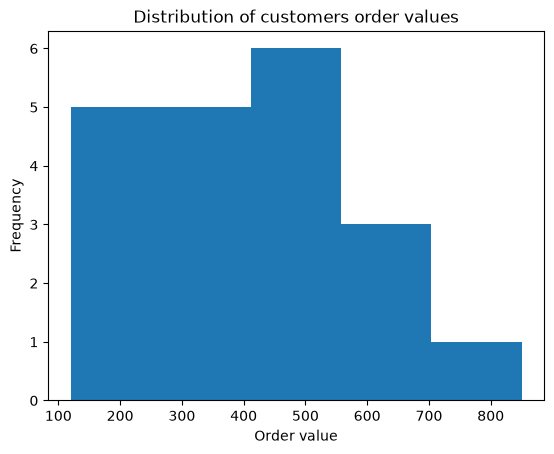

In [1]:
import matplotlib.pyplot as plt

order_values = [
    120, 150, 180, 220, 240, 270,
    310, 320, 350, 380, 420, 450,
    470, 500, 520, 550, 600, 620,
    700, 850
]

fig, ax = plt.subplots()

ax.hist(
    order_values,
    bins = 5,
    # density= True
)

ax.set_title('Distribution of customers order values')
ax.set_xlabel('Order value')
ax.set_ylabel('Frequency')

plt.show()

That's our first histogram.

### **What is frequency means?**

number observations does each distribution have.

### **Bins: The most important concept**

A histogram doesn't show every individual vlaue. It groups values into **bins**.

Suppose:
```text
Order values:

100
150
180
230
250
310
350
420
480
520
```

We could create bins:

```text
100–200
200–300
300–400
400–500
500–600
```
Conceptually:
```text
Bin 1 → 100–200
Bin 2 → 200–300
Bin 3 → 300–400
Bin 4 → 400–500
Bin 5 → 500–600
```

Each bar tells us how many observations fall inside its range.

### **controlling bins**

In Matplotlib:
```python
ax.hist(order_values, bins=5)
```
means:
> Divide the data into 5 bins.

### **why does the number of bins matter?**

> Bin selection affects what patterns we can see.

Imagine the actual distribution is:

```text
     ███████
   ███████████
 ███████████████
   ███████████
     ███████
```

But if we choose too few bins:
```text
       █████
       █████
       █████
```
it'll look like this, choosing too many bins:
```text
█ █ ██ █ █ █ █ ██ █ █ █
```
Now the graph becomes noisy.

And this is why we shouldn't blindly choose bins for every dataset.

### **Understanding Distribution Shape**

Now comes the real analyst skill.

When we look at the histogram, we don't just say:
> "There are bars."

Ask:
> "What shape does the data have?"

Several Patterns are important.

#### **1.Symmetric Distribution**

In this distribution the histogram shape would be:
- The left and right sides are roughly similar.

We can say then the histogram is approximately **symmetric**.

A famous example is the normal distribution:
```text
                    ●
                 ●     ●
              ●           ●
           ●                 ●
        ●                       ●
──────●───────────────────────────●──────
```
The center contains the most distribution.

#### **2. Right-Skewed Distribution**

This is very important in business data.

Imagine customer income:
```text
██████████████
████████████
████████
████
██
█
█
```
Most people falls at lower/middle values, while a small number have extemely high values.

- The long tail extends toward the **right**.

> Right-skewed = Positively skewed

**Real world examples**

Common candidates for _Right-skewed_ distributions:

- Income
- wealth
- transaction values
- house prices
- Customer spending
- company revenue

#### **3. Left-Skewed Distribution**

Opposite situation:
```text
              █████████████
                 █████████
                    █████
                       ██
                        █
                        █
```
The long tail extend towards the **left**.

Therefore:
> Left-skewed = Negatively skewed

Possible example:
- Exam score
- Age of retirement
- Deaht as respect to Age.


### **Why does skewness matter?**

Because it affects how we understand summary statistics.

Consider:
```text
Customer spending

₹100
₹120
₹150
₹180
₹200
₹250
₹300
₹5,000
```
The 5,000rs observation pulls the average upward. So:
```text
Mean ↑
```
While the typical customer may still spend only a few hundred rupees.

That's why analysts often compare:
```text
Mean
Meadian
Distribution
```
Rather than blindly using the mean.

### **Mean vs Median in a righ-skewed distribution**
A common pattern is:
```text
Mean > Median
```
Why? Because extremely large observations pull the mean toward the right tail.

The medain is more resistant to extreme observations.

### **Outliers**

A histogram can sometimes reveal unusual observations. We might see a long tail, those observations deserve investigations.

But here's a crucial point:
> An unusual observation is not automatically an error.

Maybe 100,000 was a legitimate corporate order.

So don't immediately delete it.

Ask:
```text
Is it valid?
     |
Yes -> understand it
No -> investigate data quality
```

### **Histogram doesn't tell you why**

Suppose you see:

```text
Huge spike around Rs 500.
```
we can say:
> Most orders are around this range.

But we cannot automatically say:
> Customers prefer Rs 500 products because of discount strategy.

That would require additional evidence.

Again:

**Visualization shows patterns; analysis investigates explanations.**

### ** Five things to ask when seeing a histogram**

Whenever we see a distribution, ask:

**1. Where is the center?**

Where are most observation concentrated?

**2. How spread out it is?**

Are values tightly packed or widely dispersed?

**3. What is the shape?**

is it:
- symmetric?
- right-skewed?
- left-skewed?
- mulimodal?

**4. Are there unusual observations?**

Look for:
- isolated regions
- long tails
- extreme values

**5. Are there multiple peaks?**

This is especially interesting.

### **Multimodal distributions**

Suppose our histogram looks like:
```text
         ███
       █████
     ███████
         ███
         ███
       █████
     ███████
         ███
```

There are two major peaks.

That's called a:
> Bimodal distribution

Why could this happen?

Maybe our customers consist of two different populations:

```text
Population A
Budget customers

Population B
Premium customers
```
This is where visualization becomes genuinely useful for business analysis.

A single average might hide this completely.


### **Practical Exercise**

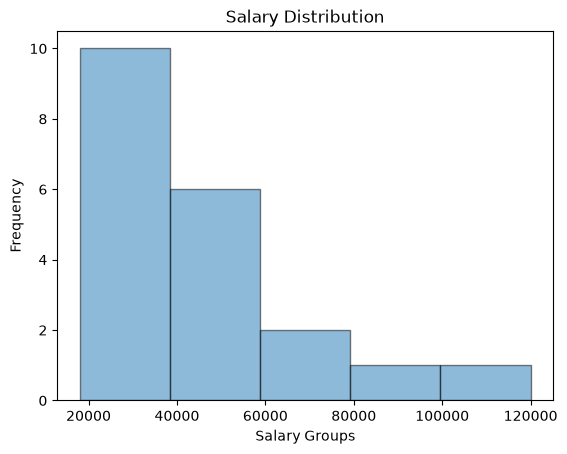

In [2]:
salaries: list = [
    18000, 20000, 22000, 25000, 27000,
    28000, 30000, 32000, 35000, 38000,
    40000, 42000, 45000, 48000, 50000,
    55000, 60000, 65000, 80000, 120000
]

fig, ax = plt.subplots()

ax.hist(
    salaries,
    bins= 5, 
    alpha=0.5,
    edgecolor='black'
)

ax.set_title('Salary Distribution')
ax.set_xlabel('Salary Groups')
ax.set_ylabel('Frequency')

plt.show()

### **Analyst Test**

Don't just code. Answer these.

Answer the following:

1. **What does a histogram represents?**
    - Answer: A histogram represents numerical values distribution across various ranges of values.

2. **What's the difference between a histogram and bar chart?**
    - Answer: A histogram shows the distribution of numerical data across multiple ranges / groups of values, e.g: how many employee's salaries lies between 20k - 40k, 40k - 80k , 80k - 100k. it'll give us the frequency/counts of the employies lies between each range of salary.<br><br>
    Whereas, The bar chart represents a comparison between variuos categories, best use on categorical variables.
    e.g.: Which region generates the more revenues, here regions are the categorical variable and the numerical value is revenues, we compare each region to each other to find out which produces the most revenue.

3. **What is a bin?**
    - Answer: A bin represents the ranges of values/ groups of values where the numerical variable lies on. such as 100k - 200k , 200k - 300k.

4. **What happens if you use too few bins?**
    - Answer: The ranges of distribution becomes too large, which leads to difficulty on analysing the skewness of data, How they are spread.

5. **What happens if you use too many bins?**
    - Answer: The ranges of distribution becomes too small, Now every values seems same, the hist becomes too noisy.

6. **What does right-skewed mean?**
    - Answer: The right skewed means that most of our observations lies on the lower range, visualization would look like a long tail towards right. e.g., Income of Customers, most of them lies on minimum range(20k - 40k) and very few would lies on the higher range (100k - 200k). some others are, wealth, transactions values, Customer order values.

7. **Why can income and customer spending often be right-skewed?**
    - Answer: Most of the population in both cases lies on the lower ranges, and very few of them lies on higher ranges, such most of the customer income would be in (20k - 40k) and few would be in (100k - 200k) same goes for customer spending, lot's them would spend few amounts and few them would be able to spend higher amounts.

8. **Why can the mean be misleading in a highly skewed dataset?**
    - Answer: Mean would be highley affected by the large observations, and highly skewed data might have long gap in distributions. if I give an example: observation [50, 58, 62, 70, 80, 120, 200] , would drastically grasp the mean towards the higher value even though most of the observation are betwee, 50-80.

9. **If a histogram has two peaks, what might that suggest?**
    - Answer: That particular situation is called bimodal distribution, it's suggest that we have two groups of observations in terms of population, e.g., we have a group of midium income consumer and might be premium consumer.

10. **If you find an extreme value, should you automatically delete it?**
    - Answer: I don't think so, extreme value doesn't always means it's an error. It might be possible value, we have to investigate the reason behind it, let's take an example: employees salaries- most of them might fall in the range of 50k - 100k, however If we see a salary of 500k that doesn't mean it's an outlier , it might be of CEOs salry. 

### **These all belongs to Box plot and IQR Section**

we'll the definitions would come later.

C:\Users\sohai_lkwn6fh\AppData\Local\Temp\ipykernel_7636\241499230.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(salaries, vert=False)


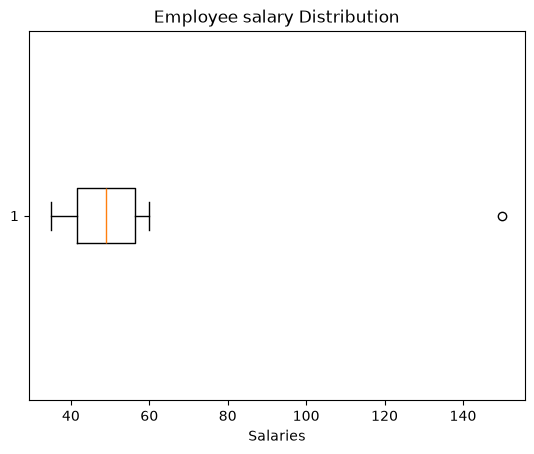

In [3]:
salaries: list = [35, 40, 42, 48, 50, 55, 60, 150]

fig, ax = plt.subplots()

ax.boxplot(salaries, vert=False)

ax.set_title("Employee salary Distribution")
ax.set_xlabel("Salaries")

plt.show()

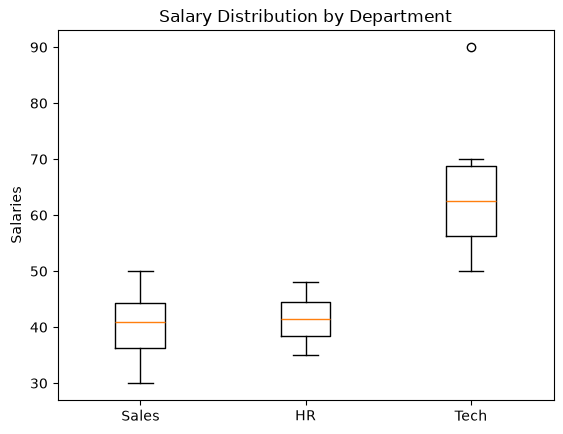

In [4]:
sales = [30, 35, 40, 42, 45, 50]
hr = [35, 38, 40, 43, 45, 48]
tech = [50, 55, 60, 65, 70, 90]

fig, ax = plt.subplots()

ax.boxplot(
    [sales, hr, tech],
    tick_labels= ['Sales', 'HR', 'Tech']
)

ax.set_title('Salary Distribution by Department')
ax.set_ylabel('Salaries')

plt.show()

1. What are Q1, Q2, and Q3?
    - Answer: Q1 is basically 25 percentile, that means 25 percent of observation fall under this value, similarly for Q2=50 percentile and Q3=75%, Q2 is also the median.

2. What is the relation between Q2 and the median?
    - Answer: Q2 is basically the median observation of the distribution, the mid value.

3. What is the five-number summary?
    - Answer: The five-number summary (minimum, 25 percentile, 50 percentile/median, 75 percentile, and maximum), just keep in mind percentile isn't as same as percentage, percentile means e.g., 25 percentile i.e 25% of observations fall under this value.

4. If Q1 = 20 and Q3 = 50 Calculate the IQR.
    - Answer: IQR = Q3 - Q1 = 50 - 20 = 30

5. What does the IQR represent in simple words?
    - Answer: IQR stands for Interquartile Range that basically shows the middle 50% of observation.

6. If Q1 = 20 and IQR = 10, calculate the upper fence using the 1.5 x IQR Rule?
    - Answer: Q3 = IQR + Q1 = 30 , upper fence = Q3 + (1.5 x IQR)= 30 + (1.5 x 10) = 45

7. If an observations lies above the upper fence, What does that tell us?
    - Answer: Those values can tell as an unsual value, but it doesn't tells us that is an error. It migh be an outlier but refering them as error is entirely depends on Business logic.

8. Does an observation being classified as a potential outlier mean we should delete it?
    - Answer: Deleting them will be entirely depends upon the business logic, they migh be an outlier and valid at same time. the best example for it is that salary of a CEO as compared to regular employees.

9. What information does the box itself represent in a box plot?
    - Answer: The five-number rules (minimu, 25 percentile, 50 percentile/median, 75 percentile and maximum).

10. Why might an analyst use a box plot instead of a histogram when comparing the distibutions of 5 different departments?
    - Answer: Instead of creating 5 different histograms at the same time, we can create a single box plot object and plot all 5 departments boxplot within the single axes. much more easier to compare and analyse, however histogram is used to see the frequency of observations within a particular bin, the size of the bin does matter to analyse the chart. whereas on the other hand Boxplot is much efficient for determining outliers and there's no required for any bins.

#### **Practical Test - Customer order Value analysis.**

Imagine you're a data analyst at an e-commerce company. You have the following 20 **Customer order values** in Rs:

```text
850, 920, 1,050, 1,100, 1,150,
1,200, 1,250, 1,300, 1,350, 1,400,
1,450, 1,500, 1,550, 1,600, 1,700,
1,800, 1,900, 2,100, 2,400, 8,500
```

The company wants to understand whether there are unusually large orders.

**Part A - Statistical Analysis**

Q1. Is the data already sorted? if not, sort it.

Q2. Find the median (Q2).

Q3. Find Q1.

Q4. Find Q3.

Q5. Calculate the IQR.

Q6. calculate the lower fence

Q7. Calculate the upper fence.

Q8. Which observation(s), if any, are  potential outliers according to the 1.5 x IQR rule?

**Part B - Analyst Interpretaion**

Q9. The order value 8,500 is much larget than most other orders. Does the IQR rule flage it as a potential outlier?

_Does that automatically mean we should delete the 8,500 order? Explain._

Q10. Suppose you investigate the 8,500 order and discover:
> Customer purchased a high-end laptop and several accesories is one legitimate transaction.

What would you do with that observation, and why?

**Bonus - Professional Thinking**

Suppose your manager says:
> "8,500 is an outlier. Remove it before calculating the average ordere value."

Would you immediately do that? 

Think carefully. Explain what you'd want to investigate **before removing it**.

1. **Q1**:
    - The data is already sorted, there's no need to sort them.

2. **Q2**:
    - since the number of observations is even: we know our elementry school formula => [(n/2)th term + (n/2+1)th term] / 2 = 10th term + 11th term / 2 i.e 1400 + 1450 / 2 = 1425 , hence the median is 1425.

3. **Q3**:
    - I know the Quartile formula, the mathematical one. Which is (quartile/100 x (n+1)) = quartile index and where n = total number of observations. let's find out: We have to find Q1 i.e. 25 percentile. 

    [25/100 x (20 + 1)] = 0.25 x 21 = 5.25 , Ahhh now here comes the tricky part. 5.25 th index we cannot find it in the observation. let's calculate 5.25 means 5th index + 25% forward to 6th index i.e 25% of the difference between 5th and 6th index. Which is (1200 - 1150) = 50 , now 12.5 would be 25% of 50 , now our Q1 = (5th index) + 12.5 = 11,50 + 12.5 = 1162.5 , hence Q1 is 1162.5, only if there isn't any calculation mistake upward.

4. **Q4**:
    - same Q3 = 75 percentile , similarly as above [75/100 x (20 + 1)] = 0.75 x 21 = 15.75 i.e (15 index + 75% of difference between 15th and 16th index) = 1700 + (1800 - 1700)/100 x 75 = 1700 + 75 = 1775, Hence the Q3 is 1775.

5. **Q5**:
    - IQR = Q3 - Q1 = 1775 - 1162.5 = 612.5

6. **Q6**:
    - lower Fence = Q1 - 1.5(IQR) = 1162.5 - 1.5(612.5) = 243.75

7. **Q7**:
    - Upper Fence = Q3 + 1.5(IQR) = 1775 + 1.5(612.5) = 2693.75

8. **Q8**:
    - 8,500 might be a potential outlier according to the 1.5 x IQR rule. And I use the term "might", which would be explained on later questions.

9. **Q9**:
    - Yes the IQR rule flag it as a potential outlier, but that doesn't mean we should delete it, since it is possible that a customer might order something premium or any product that satisfy the cost. we must investigate it, some of them might be , do we sell any product which is of that cost, it might be sum of different products too.

10. **Q10**
    - I might explit the purchase as per the product category, I think that would be better choice Since it combined laptop and several accessories. or I can left it and flag it as premium sales or something with appropriate term.

20. **Bonus Question**:
    - I would investigate the reason behind why the manager says that, might be we don't have any product which satisfies that amount, or any entry mistakes, if and if only the reason would be valid , than I'll choose the path of deleting it before calculating the average, since that amount would lead my mean towards skewness.

### **Pie Chart**

A _pie chart_ Shows how different categories contribute to a **Whole**.

Imagine a company's total sales are:
```text
Electornics       50,000 rs
Clothing          30,000 rs
Furniture         20,000 rs
```
Total:
```text
50,000 + 30,000, + 20,000 = 100,000
```

So:
- Electronics = 50%
- Clothing = 30%
- Furniture = 20%

A pie chart visually represents those portions.

The fundamental ides is:
> pie chart = part-to-whole relationship

Let's build it via Python implementation:

With Matplotlib:

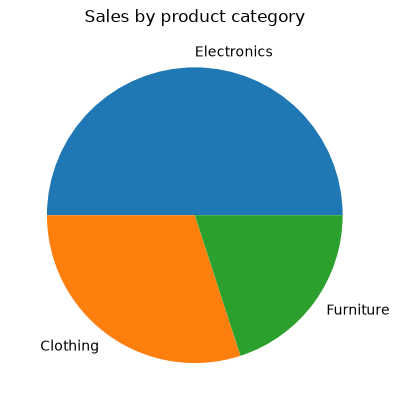

In [5]:
# Categories
categ: list = ['Electronics', 'Clothing', 'Furniture']
sales: list = [50000, 30000, 20000]

# let's create the objects.
fig, ax = plt.subplots()

ax.pie(
    sales,
    labels=categ
)

ax.set_title("Sales by product category")

plt.show()

#### **Showing percentage**

We can Use:

```python
autopct='%1.1f%%'
```

Example:

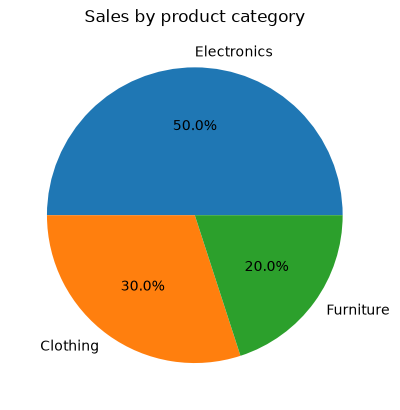

In [6]:
# Categories
categ: list = ['Electronics', 'Clothing', 'Furniture']
sales: list = [50000, 30000, 20000]

# let's create the objects.
fig, ax = plt.subplots()

ax.pie(
    sales,
    labels=categ,
    autopct='%1.1f%%'
)

ax.set_title("Sales by product category")

plt.show()

#### **Expllding a slice**

Sometimes we want to visually emphasize one particular category.

Matplotlib provides:
```python
explode
```

Example:

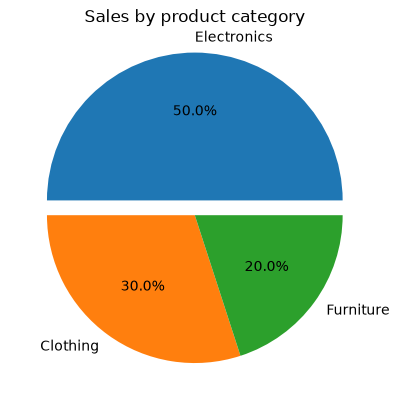

In [7]:
# Categories
categ: list = ['Electronics', 'Clothing', 'Furniture']
sales: list = [50000, 30000, 20000]

# let's create the objects.
fig, ax = plt.subplots()

ax.pie(
    sales,
    labels=categ,
    autopct='%1.1f%%',
    explode=[0.1, 0, 0]
)

ax.set_title("Sales by product category")

plt.show()

Here:
```python
explode = [0.1, 0, 0]
```
means:
```text
Electronics -> move slightly outward
Clothing -> normal
Furniture -> normal
```
### **But here's an important analyst rule**

Pie charts are often overused.

They're appropriate when you have: 

**A small number of categories + meaningful part-to-whole relationship.**

For example:
```text
Company revenue:

Product A → 50%
Product B → 30%
Product C → 20%
```

That's reasonable.

But imagine:
```text
25 different product categories
```
A pie chart becomes difficult to read.

In that situation, a **bar chart** will generally make category comparisons easier.

so:
> Pie chart -> composition

> Bar chart -> comparison

That's an important distinction.

**Dont confuse them:**

if our question is:
> "What percentage of total sales comes from each category?"

A pie chart can work.

If our quesion is:
> "What category generate the most sales?"

A bar chart is generally easier for comparing the values precisely.

This is the kind of **Chart-selection thinking** we need to develop.

### **Mini-test**

Q1. What is the main purpose of a pie chart?

Q2. When is a pie chart appropriate?

Q3. Why can a pie chart become difficult to interpret when there are many categories?

Q4. What does autopct="%1.1f%%" do?

Q5. What does the explode parameter do?

Q6. Suppose a company's revenue is:
```text
Product A = ₹60,000
Product B = ₹25,000
Product C = ₹15,000
```
What percentage of total revenue does each product represent?

Q7. If your business question is "Which product generated the highest revenue?", would you choose a pie chart or bar chart? Explain your reasoning.

### **Answers**
1. How much different categories contributes as a whole.

2. When we have optimum number of categories and a reasonable way to combine them as a whole.

3. Well the chart becomes complex to read having all of the categories to the same axes.

4. Tell convert them in percentage with 1 decimal place and keep the "%" symbol.

5. The explode parameter slightly move a category upward to get a distinction.

6. Product A = 60%, Product B = 25%, and Product C = 15%

7. Well choosing bar chart must be appropriate here, since we are comparing different categories to each other, not finding out which category contributes the more or how much does each category contributes to total sales.

### **Legends**

A _legend_ tells viewers what different visual elements in a chart represent.

This become especially important when we have multiple lines, bars, or datasets on the same chart.

For example we wanna compare sales of two products:

We'll see that in every kinds of charts containing **multiple datasets on the same Axes.**

#### **1. Multiple Line Plots**

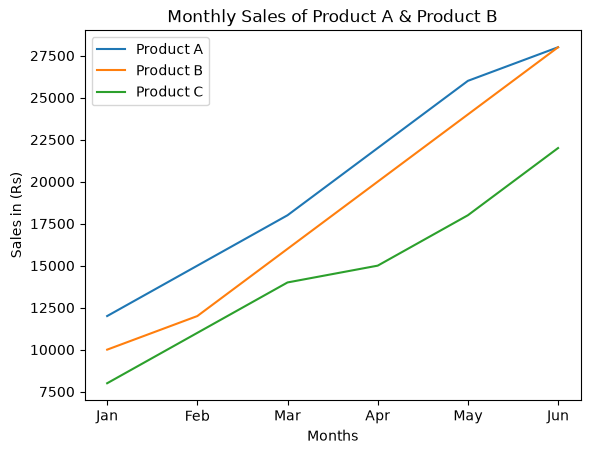

In [8]:
months: list = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun']

# Sales of:
product_a: list = [12000, 15000, 18000, 22000, 26000, 28000]
product_b: list = [10000, 12000, 16000, 20000, 24000, 28000]

# we can even add more:
product_c: list = [8000, 11000, 14000, 15000, 18000, 22000]

fig, ax = plt.subplots()

ax.plot(
    months,
    product_a,
    label="Product A",
    # marker='o'
)

ax.plot(
    months,
    product_b,
    label='Product B',
    # marker='o'
)

ax.plot(
    months,
    product_c,
    label='Product C',
    # marker='o'
)
ax.set_title('Monthly Sales of Product A & Product B')
ax.set_xlabel('Months')
ax.set_ylabel('Sales in (Rs)')
ax.legend()

plt.show()

All three lines have:
- Same X-axis
- Same Y-axis
- Same Axes

But each line represents a different variable/category.

#### **2. Multiple Scatter Plots**

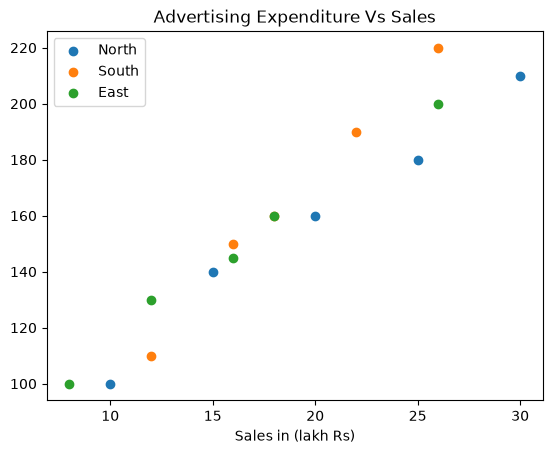

In [9]:
# We use scatterplot to show the relationship between two variables, e.g
# Advertisment expanse with Sales.

ad_north: list = [10, 15, 20, 25, 30]
sales_north: list = [100, 140, 160, 180, 210]

ad_south: list = [12, 16, 18, 22, 26]
sales_south: list = [110, 150, 160, 190, 220]

ad_east: list = [8, 12, 16, 18, 26]
sales_east: list = [100, 130, 145, 160, 200]

fig, ax = plt.subplots()

ax.scatter(
    ad_north,
    sales_north,
    label = 'North'
)

ax.scatter(
    ad_south,
    sales_south,
    label = 'South'
)

ax.scatter(
    ad_east,
    sales_east,
    label = 'East'
)

ax.set_title("Advertising Expenditure Vs Sales")
ax.set_xlabel('Advertising Expenditure (lakh Rs)')
ax.set_xlabel('Sales in (lakh Rs)')

ax.legend()

plt.show()



Now the Axes contains three groups of points. Conceptually we're distinguishing three datasets.

With the legend, we can ask:
> Does the relationship between advertising and sales looks different across regions?

That's much more analytical.

#### **3. Multiple Bar Series**

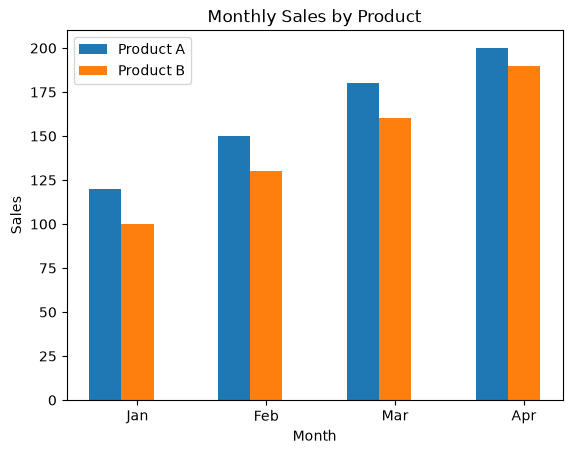

In [24]:
# import matplotlib.pyplot as plt
import numpy as np

months = ["Jan", "Feb", "Mar", "Apr"]

product_a = [120, 150, 180, 200]
product_b = [100, 130, 160, 190]
product_c = [80, 110, 140, 170]

x = np.arange(len(months))
width = 0.25

fig, ax = plt.subplots()

ax.bar(x - width, product_a, width, label="Product A")
ax.bar(x, product_b, width, label="Product B")
# ax.bar(x + width, product_c, width, label="Product C")

ax.set_title("Monthly Sales by Product")
ax.set_xlabel("Month")
ax.set_ylabel("Sales")

ax.set_xticks(x)
ax.set_xticklabels(months)

ax.legend()

plt.show()

#### **Why `x` is needed**

We cannot do math on text. If we try to shift a bar to the left by subtracting 0.25 from the word "Jan", Python will throw an error. We must convert our categorical text into a numerical grid.

- `len(month)` equals 4. 
- `np.arange(4)` generates a NumPy array containing the exact center point: `[0, 1, 2, 3]`.
- Now, "jan" lives at coordinate 0, "Feb" at 1, "Mar" at 2, and "Apr" at 3.

#### **Setting the `width`**

By declaring `width=0.25`, we are deciding that each bar takes up exactly a quarter of a unit on the chart.

#### **The Vectorized Math(The `ax.bar` lines)**

Because `x` is a NumPy array, it behaves differently than a standard Python list. when we add or subtract a number from it. NumPy applies that math to _every_ number in the array simultaneously. Grasping this concept - vectorization - is fundamental for writing the highly optimized, industry-level code we need for heavy data analysis and ML models.

Here is the exact mechanical breakdown of how the math prevents the bars from overlapping.
#### **1. Product A (shifted left): `ax.bar(x-width,...)`**

NumPy calculates `[0, 1, 2, 3] - 0.25`. The resulting center coordinates for Product A are `[-0.25, 0.75, 1.75, 2.75]`. The bars are drawn slightly to the left of the main month coordinates.

#### **2. Product B (Dead Center): `ax.bar(x, ...)`**

The coordinates remains `[0, 1, 2, 3]`. Product B is drawn exactly in the middle of the cluster. The left edge of Product B perfectly touches the right edge of Product A.

#### **3. Product C (Shifted Right): `ax.bar(x+width, ...)`**
NumPy calculates `[0, 1, 2, 3] + 0.25.`
The resulting center coordinates for Product C are `[0.25, 1.25, 2.25, 3.25].` These bars are drawn slightly to the right, perfectly touching the right edge of Product B.

By manually forcing the centers of the bars to be exactly 0.25 units apart (which perfectly matches their physical thickness), you create a seamless side-by-side cluster for each month.


#### **Multiple Histograms**

Now let's put mulitple distributions on the same Axes.

Suppose we want to compare order values from three customer segments.

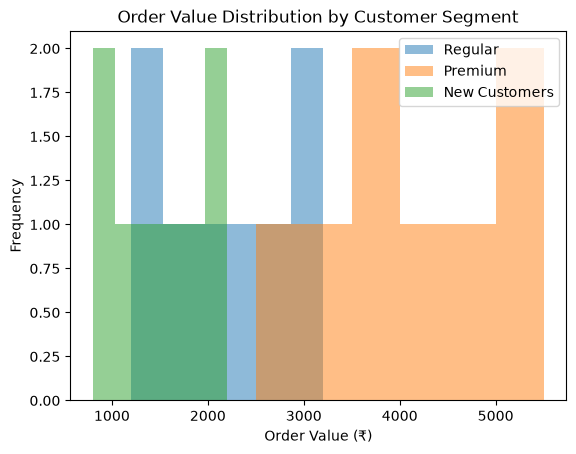

In [11]:
# import matplotlib.pyplot as plt

regular = [1200, 1500, 1800, 2100, 2400, 2600, 3000, 3200]
premium = [2500, 3000, 3500, 3800, 4200, 4500, 5000, 5500]
new = [800, 1000, 1200, 1400, 1600, 1800, 2000, 2200]

fig, ax = plt.subplots()

ax.hist(regular, bins=6, alpha=0.5, label="Regular")
ax.hist(premium, bins=6, alpha=0.5, label="Premium")
ax.hist(new, bins=6, alpha=0.5, label="New Customers")

ax.set_title("Order Value Distribution by Customer Segment")
ax.set_xlabel("Order Value (₹)")
ax.set_ylabel("Frequency")

ax.legend()

plt.show()

The `alpha=0.5` is useful because the histograms overlap.

If they were completely opaque, one histogram could hide another.

**This is really important idea:**

Multiple datasets don't automatically mean:
> "Put everything together."

We have to think about **readability**.

Three distributions may be useful. Ten distributions on one histogram? Probably a mess.

#### **Multiple Pie Charts?**

Here's where we need to be careful.

We generally **don't put multiple datasets into one pie chart.

why?

A pie chart represents:
> One whole divided into parts.

So this is an important limitation.
> **Not every chart type handles multiple variables equally well.**

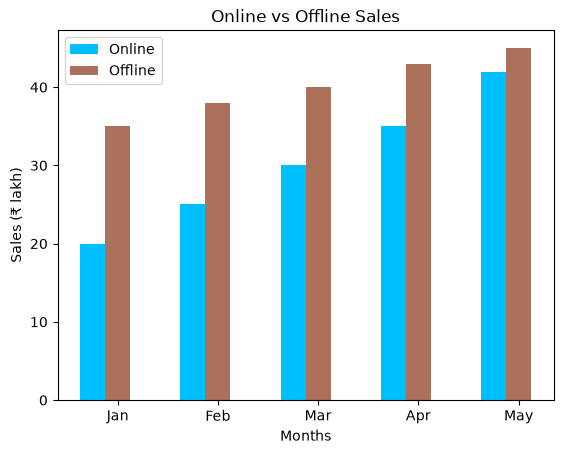

In [31]:
months: list = ['Jan', 'Feb', 'Mar', 'Apr', 'May']

online: list = [20, 25, 30, 35, 42]
offline: list = [35, 38, 40, 43, 45]

x: np.ndarray = np.arange(len(months))
width = 0.25

fig, ax = plt.subplots()

ax.bar(x-width, online, width, label='Online', color="#00BFFF")
ax.bar(x, offline, width, label='Offline', color='#AC715B')

ax.set_title('Online vs Offline Sales')
ax.set_xlabel('Months')
ax.set_ylabel('Sales (₹ lakh)')

ax.set_xticks(x)
ax.set_xticklabels(months)

ax.legend()

plt.show()

### **A complete professional example for markers and charts**

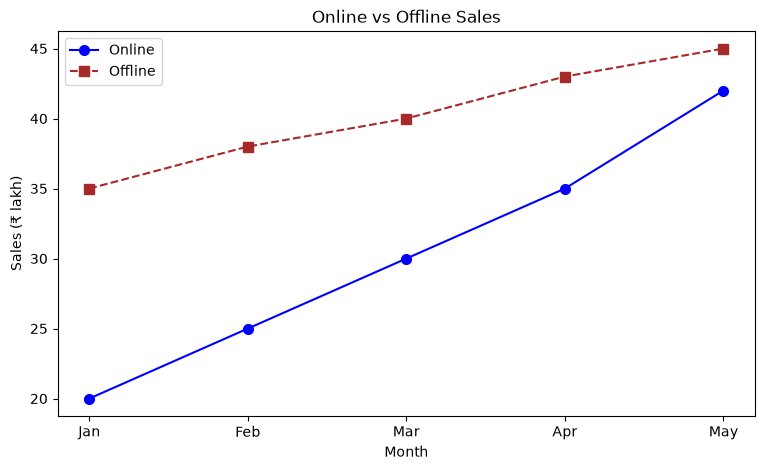

In [32]:
months = ["Jan", "Feb", "Mar", "Apr", "May"]

online = [20, 25, 30, 35, 42]
offline = [35, 38, 40, 43, 45]

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    months,
    online,
    color="blue",
    marker="o",
    linestyle="-",
    markersize=7,
    label="Online"
)

ax.plot(
    months,
    offline,
    color="brown",
    marker="s",
    linestyle="--",
    markersize=7,
    label="Offline"
)

ax.set_title("Online vs Offline Sales")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (₹ lakh)")

ax.legend()

plt.show()